# Dallas 311 — Predicting Missed Deadlines (Modeling)

**Question:** When someone files a 311 request in Dallas, can we predict right away whether the city will miss its promised deadline?

| | |
| --- | --- |
| **Target variable** | `missed_deadline`: 1 = closed after the due date, 0 = closed on time |
| **Task type** | Supervised **binary classification** (predict one of two outcomes) |
| **Unit of analysis** | One 311 service request, at the moment it is filed |
| **Primary metric** | **F1 score for the "missed" class** |
| **Secondary metrics** | Recall, precision, ROC-AUC, PR-AUC, accuracy |

**Objectives**
1. Build and report a defensible **baseline** before any improvements.
2. Test whether additional **preprocessing and feature engineering** improve on that baseline, and report every step's effect, including steps that don't help.
3. **Compare several model types** using metrics suited to an imbalanced target.
4. Identify **which factors drive missed deadlines**, and check whether the model works equally well across council districts.

**Workflow of this notebook:** Data → Minimum cleaning → Train/validation/test split → **Baseline** → Additional preprocessing & feature engineering → Model selection → Tuning → **Final model** on the test set → Interpretation → Findings

## Glossary: every term used in this notebook

**The setup**
- **Feature:** an input the model uses to make a prediction (e.g., request type, council district).
- **Target:** the thing we're trying to predict (`missed_deadline`).
- **Classification:** predicting a category (here: missed or on time) rather than a number.
- **Training set:** the data the model learns from (Jan–Jul 2025).
- **Validation set:** data held out to *compare and tune* models while we work (Aug–Sep 2025).
- **Test set:** data locked away until the very end, used *once* to measure the final model honestly (Oct–Dec 2025).
- **Data drift:** when the data the model sees in the future looks different from what it was trained on.
- **Data leakage:** accidentally giving the model information it wouldn't have in real life (like the closed date). It makes results look great but they're fake.
- **Class imbalance:** when one outcome is much rarer than the other. Only ~11% of requests miss their deadline.
- **Pipeline:** a chain of steps (cleaning → encoding → model) bundled together so every step is learned *only from the training data*, which prevents leakage.

**Preprocessing**
- **Imputation:** filling in missing values (here, missing categories become "Unknown").
- **One-hot encoding:** turning a category column into many 0/1 columns, one per category (e.g., `department = Sanitation` becomes a column that is 1 for Sanitation requests and 0 otherwise). Needed for logistic regression.
- **Ordinal encoding:** turning each category into a number (Sanitation = 0, Parks = 1, ...). Fine for tree models, which only split on values and don't treat 2 as "bigger" than 1 in a meaningful way.
- **Scaling (standardization):** rescaling numeric features to a similar range so no feature dominates just because of its units. Needed for logistic regression, not for trees.
- **Log transform:** compressing very large values (e.g., 1 day vs. 180 days) so a few extreme values don't dominate.
- **Feature engineering:** creating a new feature from existing data because we expect it to carry signal.
- **Department workload (backlog):** how many requests the same department already had open at the moment a new request was filed. Our own engineered feature.
- **Class weights:** telling the model that mistakes on the rare class ("missed") cost more, so it doesn't just ignore it.
- **SMOTE:** creates synthetic examples of the rare class by blending real ones, to balance the training data.

**Models**
- **Baseline:** the simple starting point that every later result is compared against.
- **Majority-class baseline:** always predicts the most common outcome ("on time"). Shows how misleading accuracy is.
- **Logistic regression:** adds up weighted features to produce a probability. Simple, fast and easy to explain.
- **Decision tree:** a flowchart of yes/no questions ("Is it an Animal Services request? Is the promised time under 2 days?") that ends in a prediction.
- **Random forest:** hundreds of decision trees, each trained on a random slice of the data, that vote on the answer. More accurate and stable than one tree.
- **Gradient boosting:** builds trees one after another, where each new tree focuses on fixing the mistakes of the previous ones. Usually the strongest model for tabular data.
- **Hyperparameter:** a setting chosen *before* training (e.g., how deep trees can grow), as opposed to what the model learns.
- **Hyperparameter tuning:** trying many settings and keeping the one that scores best on the validation set.
- **Overfitting:** when a model memorizes the training data and does worse on new data.
- **Decision threshold:** the probability cutoff for predicting "missed". The default is 0.5; lowering it catches more misses but raises false alarms.

**Metrics**
- **Confusion matrix:** a 2×2 table of correct and incorrect predictions:
  - *True positive (TP):* predicted missed, actually missed
  - *False positive (FP):* predicted missed, actually on time (false alarm)
  - *False negative (FN):* predicted on time, actually missed (a miss we didn't catch)
  - *True negative (TN):* predicted on time, actually on time
- **Accuracy:** share of all predictions that are correct. Misleading here: always guessing "on time" is ~89% accurate.
- **Precision:** of the requests we *flagged* as likely to miss, what share actually missed? (TP ÷ (TP + FP))
- **Recall:** of the requests that *actually* missed, what share did we catch? (TP ÷ (TP + FN))
- **F1 score:** a single score that balances precision and recall (their harmonic mean). Our main metric.
- **ROC-AUC:** how well the model *ranks* missed requests above on-time ones, across all thresholds. 0.5 = random guessing, 1.0 = perfect.
- **PR-AUC (average precision):** like ROC-AUC but focused on the rare class, so it's more honest for imbalanced data. Random guessing scores about 0.11 here (the miss rate).
- **Permutation importance:** how much the model's score drops when one feature's values are shuffled. A big drop means the model relies on that feature.

## Setup

In [1]:
import sys
import time
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from src.prep import load_data

SEED = 42
BLUE, RED, GRAY, GREEN = "#3a6ea5", "#c0392b", "#9aa5b1", "#1e8449"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 200)

## 1. Minimum cleaning

Only what the baseline *cannot run without*. Everything else is deliberately saved for later so we can measure whether it helps.

| Step | Why |
| --- | --- |
| Keep only requests **with a due date** | Without a due date there's no target. These are almost all *Code Concern* requests, which have no deadline. |
| Drop **2 requests that closed before they were created** | Impossible values: data entry errors. |
| **Merge duplicate department names** (e.g., *Sanitation Services → Sanitation*) | The same department under two names would be treated as two different departments. |
| **Remove leakage columns** (`closed_date`, `days_to_close`, `outcome`, `status`) | These are only known *after* the request is finished. Using them would be cheating. |

The last three are done by `load_data()` in `src/prep.py`.

In [2]:
df_all = load_data()  # every request, including those with no due date (used later for workload)
df = df_all[df_all["missed_deadline"].notna()].copy()
df["missed_deadline"] = df["missed_deadline"].astype(int)

# District as a text label ("4"), not a number: District 14 isn't "more" than District 4
d = df["city_council_district"]
df["city_council_district"] = d.astype(object).where(d.notna(), np.nan).map(
    lambda v: v if pd.isna(v) else str(int(v)))

print(f"Requests with a due date: {len(df):,}")
print(f"Missed-deadline rate: {df['missed_deadline'].mean():.1%}")

Requests with a due date: 276,378
Missed-deadline rate: 11.2%


## 2. Train / validation / test split, by time

We split **by month, not randomly**. In real life the city would train on past requests and predict future ones, so the test set must be *later* than the training data. A random split would let the model peek at the future.

| Set | Months | Used for |
| --- | --- | --- |
| **Training** | Jan–Jul 2025 | Learning |
| **Validation** | Aug–Sep 2025 | Comparing steps, choosing models, tuning |
| **Test** | Oct–Dec 2025 | Measuring the final models **once**, at the end |

The split happens **before** any encoding, scaling or imputation, so nothing is learned from the validation or test data.

In [3]:
month = df["created_date"].dt.month
train = df[month <= 7]
val = df[month.between(8, 9)]
test = df[month >= 10]
train_val = df[month <= 9]

y_train, y_val, y_test, y_train_val = (s["missed_deadline"] for s in (train, val, test, train_val))

split_summary = pd.DataFrame({
    "months": ["Jan–Jul", "Aug–Sep", "Oct–Dec"],
    "requests": [len(train), len(val), len(test)],
    "missed_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Training", "Validation", "Test"])
split_summary.style.format({"requests": "{:,}", "missed_rate": "{:.1%}"})

,months,requests,missed_rate
Training,Jan–Jul,"171,767",11.6%
Validation,Aug–Sep,"45,387",10.7%
Test,Oct–Dec,"59,224",10.5%


**What this means:** all three periods have a similar missed rate (around 11%), so the target doesn't shift much over time. That's a good sign the training data is representative of the test period (little *data drift* in the target).

## 3. Baseline

We need a starting number that everything later is compared against. Two baselines:

1. **Majority class:** always predict "on time". This is the floor, and it shows why accuracy alone is misleading.
2. **Logistic regression on the minimum features:** a simple, standard first model.

**Minimum features** (5 categories, all known when the request is filed): request type, department, priority, how it was received, council district.

**Minimum preprocessing inside the pipeline:** missing categories → "Unknown" (154 priorities, 15 intake methods, 558 districts are missing), then one-hot encoding. Both are learned from the training set only.

**Metric:** F1 on the "missed" class, because we care about *catching* missed deadlines (recall) without flooding the city with false alarms (precision). Accuracy is reported but not used to choose models.

In [4]:
def evaluate(y_true, proba, threshold=0.5):
    """All metrics for one set of predicted probabilities."""
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }


steps = []  # every improvement step and its validation scores


def run_step(name, pipe, features, note=""):
    t0 = time.time()
    pipe.fit(train[features], y_train)
    proba = pipe.predict_proba(val[features])[:, 1]
    row = {"Step": name, **evaluate(y_val, proba), "Note": note}
    steps.append(row)
    print(f"{name:<45} F1 {row['F1']:.3f}  recall {row['Recall']:.3f}  "
          f"precision {row['Precision']:.3f}  ({time.time() - t0:.0f}s)")
    return pipe


CAT_MIN = ["service_request_type", "department", "priority",
           "method_received_description", "city_council_district"]

def one_hot(cols, min_frequency=None):
    return make_pipeline(
        SimpleImputer(strategy="constant", fill_value="Unknown"),
        OneHotEncoder(handle_unknown="infrequent_if_exist" if min_frequency else "ignore",
                      min_frequency=min_frequency),
    )

run_step("0. Majority class (always 'on time')",
         DummyClassifier(strategy="most_frequent"), CAT_MIN,
         "Floor: never catches a single missed deadline")

baseline_pipe = run_step(
    "1. Logistic regression, minimum features",
    Pipeline([("prep", ColumnTransformer([("cat", one_hot(CAT_MIN), CAT_MIN)])),
              ("model", LogisticRegression(max_iter=2000))]),
    CAT_MIN, "Baseline")

0. Majority class (always 'on time')          F1 0.000  recall 0.000  precision 0.000  (0s)


1. Logistic regression, minimum features      F1 0.104  recall 0.056  precision 0.671  (1s)


In [5]:
pd.DataFrame(steps).set_index("Step").drop(columns="Note").round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Step,,,,,,
0. Majority class (always 'on time'),0.893,0.000,0.000,0.000,0.50,0.107
"1. Logistic regression, minimum features",0.897,0.671,0.056,0.104,0.72,0.269


**What this means:**
- The **majority-class** model looks ~89% accurate but has **0 recall**: it never catches a single missed deadline. This is exactly why accuracy can't be our metric.
- The **baseline logistic regression** ranks requests well (ROC-AUC well above 0.5), but at the default 0.5 threshold it barely flags anything as "missed". Because missed deadlines are rare, the model almost never becomes confident enough to predict one. Its F1 is the number every later step must beat.

## 4. Additional preprocessing and feature engineering

Each step is added **one at a time** on top of the previous one, and scored on the **validation set**, so we can say exactly which change caused which gain. Steps that don't help are kept in the table: reporting them is part of honest work.

| Step | What it does | Why we expected it to help |
| --- | --- | --- |
| 2. Class weights | Makes mistakes on "missed" requests cost ~8× more during training | The model was ignoring the rare class |
| 3. Group rare request types | Request types with < 50 training examples become one "infrequent" group | 49 of 197 types are too rare to learn from reliably |
| 4. Promised time | Days between filing and the due date, log-transformed and scaled | A 4-hour deadline is much easier to miss than a 30-day one |
| 5. Timing features | Weekday and hour the request was filed | EDA showed weekday patterns |
| 6. **Department workload** (our engineered feature) | How many requests the department already had open when this one was filed (log-transformed and scaled) | A department buried in a backlog is more likely to miss a new deadline |
| 7. SMOTE (instead of class weights) | Creates synthetic "missed" examples to balance the training data | An alternative way to handle imbalance (taught in HW3) |

**Why promised time comes from the due date:** the text column `ert_estimated_response_time` (e.g., "4 Business Days") is missing for 8,273 requests, while the due date is always present for these rows. The due date is set when the request is filed, so it's not leakage.

**Why "month filed" is *not* a feature:** the EDA showed seasonal patterns, so month looked useful. But we only have one year of data, so the test months (Oct–Dec) **never appear in training**. In a first version of this notebook, tree models treated October–December as if they were September, and gradient boosting's test PR-AUC dropped from **0.336 without month to 0.274 with it**. A model can't learn about months it has never seen, so month was removed. This is a form of **data drift**: a feature that looks harmless in training breaks on future data.

In [6]:
weighted = LogisticRegression(max_iter=2000, class_weight="balanced")

run_step("2. + class weights", Pipeline([
    ("prep", ColumnTransformer([("cat", one_hot(CAT_MIN), CAT_MIN)])),
    ("model", weighted)]), CAT_MIN)

run_step("3. + group rare request types", Pipeline([
    ("prep", ColumnTransformer([("cat", one_hot(CAT_MIN, min_frequency=50), CAT_MIN)])),
    ("model", weighted)]), CAT_MIN)

NUM = ["promised_days"]
log_scale = make_pipeline(SimpleImputer(strategy="median"),
                          FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                          StandardScaler())

run_step("4. + promised time (log, scaled)", Pipeline([
    ("prep", ColumnTransformer([("cat", one_hot(CAT_MIN, 50), CAT_MIN),
                                ("num", log_scale, NUM)])),
    ("model", weighted)]), CAT_MIN + NUM)

TIME = ["created_weekday", "created_hour"]

def lr_prep(nums):
    return ColumnTransformer([
        ("cat", one_hot(CAT_MIN, 50), CAT_MIN),
        ("num", log_scale, nums),
        ("time", OneHotEncoder(handle_unknown="ignore"), TIME),
    ])

_ = run_step("5. + timing features (weekday, hour)",
             Pipeline([("prep", lr_prep(NUM)), ("model", weighted)]), CAT_MIN + NUM + TIME)

# Step 6 is defined in the next cell (department workload)

2. + class weights                            F1 0.304  recall 0.596  precision 0.204  (2s)


3. + group rare request types                 F1 0.304  recall 0.601  precision 0.204  (2s)


4. + promised time (log, scaled)              F1 0.306  recall 0.604  precision 0.205  (2s)


5. + timing features (weekday, hour)          F1 0.309  recall 0.622  precision 0.206  (3s)


### Step 6: engineering the department workload feature

For each request, count how many requests **in the same department** were already open (created but not yet closed) at the moment it was filed. This uses *every* 2025 request, including Code Concern requests without a due date, because they also take up the department's time.

**Is this leakage?** No. At the moment a request is filed, the city already knows which earlier requests are still open. We only count requests created **before** this one that had **not closed yet** at that moment.

**Known limitation:** the data starts on Jan 1, 2025 and only includes requests that were eventually closed, so the backlog is undercounted, especially in early January.

count    276378.0
mean       1318.0
std        1293.0
min           0.0
25%         385.0
50%         710.0
75%        2379.0
max        7290.0
Name: dept_open_requests, dtype: float64


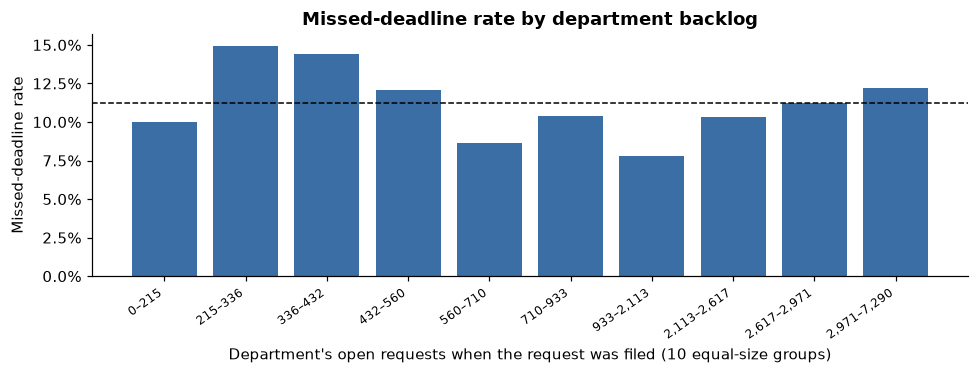

In [7]:
workload = pd.Series(0.0, index=df_all.index)
for dept, g in df_all.groupby("department"):
    created = np.sort(g["created_date"].values)
    closed = np.sort(g["closed_date"].dropna().values)
    t = g["created_date"].values
    # opened before t, minus closed before t = still open at t
    workload[g.index] = np.searchsorted(created, t, "left") - np.searchsorted(closed, t, "left")

df["dept_open_requests"] = workload[df.index]
for part in (train, val, test, train_val):
    part.loc[:, "dept_open_requests"] = df.loc[part.index, "dept_open_requests"]

print(df["dept_open_requests"].describe().round(0))

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = pd.qcut(df["dept_open_requests"], 10, duplicates="drop")
rate = df.groupby(bins, observed=True)["missed_deadline"].mean()
ax.bar(range(len(rate)), rate.values, color=BLUE)
ax.set_xticks(range(len(rate)), [f"{int(i.left):,}–{int(i.right):,}" for i in rate.index],
              rotation=35, ha="right", fontsize=8)
ax.axhline(df["missed_deadline"].mean(), color="black", linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Department's open requests when the request was filed (10 equal-size groups)")
ax.set_ylabel("Missed-deadline rate")
ax.set_title("Missed-deadline rate by department backlog")
plt.tight_layout()
plt.show()

In [8]:
NUM_ALL = ["promised_days", "dept_open_requests"]
FEATURES_LR = CAT_MIN + NUM_ALL + TIME

run_step("6. + department workload (engineered)",
         Pipeline([("prep", lr_prep(NUM_ALL)), ("model", weighted)]), FEATURES_LR)

_ = run_step("7. SMOTE instead of class weights",
         ImbPipeline([("prep", lr_prep(NUM_ALL)), ("smote", SMOTE(random_state=SEED)),
                      ("model", LogisticRegression(max_iter=2000))]), FEATURES_LR)

6. + department workload (engineered)         F1 0.296  recall 0.639  precision 0.193  (3s)


7. SMOTE instead of class weights             F1 0.295  recall 0.647  precision 0.191  (13s)


In [9]:
ladder = pd.DataFrame(steps).set_index("Step")
ladder["F1 change"] = ladder["F1"].diff()
ladder.drop(columns="Note").style.format("{:.3f}", na_rep="").format(
    "{:+.3f}", subset=["F1 change"], na_rep="")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,F1 change
Step,,,,,,,
0. Majority class (always 'on time'),0.893,0.000,0.000,0.000,0.500,0.107,
"1. Logistic regression, minimum features",0.897,0.671,0.056,0.104,0.720,0.269,+0.104
2. + class weights,0.710,0.204,0.596,0.304,0.723,0.270,+0.200
3. + group rare request types,0.707,0.204,0.601,0.304,0.721,0.271,+0.000
"4. + promised time (log, scaled)",0.708,0.205,0.604,0.306,0.726,0.270,+0.001
"5. + timing features (weekday, hour)",0.704,0.206,0.622,0.309,0.726,0.269,+0.004
6. + department workload (engineered),0.677,0.193,0.639,0.296,0.725,0.266,-0.013
7. SMOTE instead of class weights,0.670,0.191,0.647,0.295,0.725,0.265,-0.002


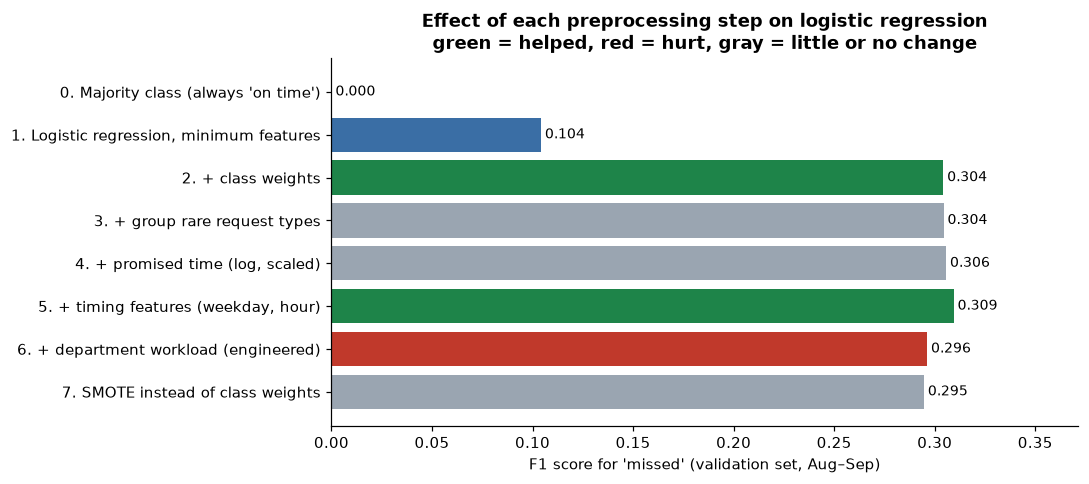

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [GRAY, BLUE] + [GREEN if d > 0.002 else (RED if d < -0.002 else GRAY)
                        for d in ladder["F1 change"].iloc[2:]]
bars = ax.barh(ladder.index[::-1], ladder["F1"][::-1], color=colors[::-1])
for b, v in zip(bars, ladder["F1"][::-1]):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {v:.3f}", va="center", fontsize=9)
ax.set_xlabel("F1 score for 'missed' (validation set, Aug–Sep)")
ax.set_xlim(0, ladder["F1"].max() * 1.2)
ax.set_title("Effect of each preprocessing step on logistic regression\n"
             "green = helped, red = hurt, gray = little or no change")
plt.tight_layout()
plt.show()

**What this means:**
- **Class weights were the single biggest gain:** F1 tripled from 0.104 to 0.304. Without them, the model almost never predicts "missed" (recall 6%).
- Grouping rare request types (+0.000) and adding promised time (+0.001) changed almost nothing. Timing features gave a small gain (+0.004). We report these anyway: steps that don't help are still results.
- **Department workload slightly *hurt* logistic regression (−0.013).** The backlog chart above shows why: the relationship isn't a straight line (missed rates are high at both 215–560 and 2,600+ open requests, lower in between). Logistic regression can only use straight-line relationships. Tree models can capture this shape, and in the final model workload becomes the **2nd most important feature** (Section 9).
- **SMOTE did not beat class weights** (F1 0.295 vs. 0.296 with the same features) and was about 4× slower, so class weights are kept.

## 5. Model selection

Now we compare different **types** of models, all using the best preprocessing from above (class weights + all features). Tree models also get **location** (latitude/longitude), since trees can split a map into areas while logistic regression can't use raw coordinates meaningfully.

| Model | What it is, in plain English | Why we tried it | Strength | Limitation | Needs scaling / one-hot? |
| --- | --- | --- | --- | --- | --- |
| **Logistic regression** | Adds up weighted features to get a probability | Simple, explainable baseline | Fast; each weight shows a feature's direction | Assumes each feature's effect adds up in a straight line; can't capture combinations | Yes, both |
| **Decision tree** | A flowchart of yes/no questions | Captures combinations like "Animal Services *and* short deadline" | Easy to read and explain | One tree overfits easily; unstable | No |
| **Random forest** | Hundreds of trees on random slices of the data, voting together | Fixes a single tree's overfitting | Strong on mixed tabular data; robust | Slower; harder to interpret than one tree | No |
| **Gradient boosting** (HistGradientBoosting) | Trees built one after another, each fixing the previous ones' mistakes | Usually the strongest model on tabular data | Highest accuracy potential; handles missing values and categories natively; fast on large data | More settings to tune; can overfit if over-tuned | No |

**Not tried:** k-nearest neighbors and support vector machines. Both compare every request against many others, which is very slow on ~170,000 training rows, and they need heavy scaling of one-hot data.

All models use **class weights** so they don't ignore the rare class, and all are scored on the same validation set.

**How we pick the winner: PR-AUC, not F1.** F1 depends on the 0.5 cutoff, and each model's probabilities are scaled differently, so one fixed cutoff favors some models over others. **PR-AUC** measures how well a model ranks risky requests at *every* cutoff, so it compares models fairly. We pick the model with the best validation PR-AUC, then tune its cutoff to maximize F1 (Section 6).

In [11]:
GEO = ["latitude", "longitude"]
FEATURES_TREE = CAT_MIN + NUM_ALL + TIME + GEO
TREE_CATS = CAT_MIN + ["created_weekday"]
TREE_NUMS = NUM_ALL + ["created_hour"] + GEO

def tree_prep():
    # Ordinal encoding: each category becomes a number. Unseen or missing categories become NaN,
    # which the tree models below can handle. No scaling needed for trees.
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               encoded_missing_value=np.nan), TREE_CATS),
        ("num", "passthrough", TREE_NUMS),
    ])

def tree_prep_filled():
    # Decision tree / random forest in scikit-learn need no missing values, so fill with -1
    return make_pipeline(tree_prep(), SimpleImputer(strategy="constant", fill_value=-1))

models = {
    "Logistic regression": (Pipeline([("prep", lr_prep(NUM_ALL)), ("model", weighted)]), FEATURES_LR),
    "Decision tree": (Pipeline([("prep", tree_prep_filled()), ("model", DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEED))]), FEATURES_TREE),
    "Random forest": (Pipeline([("prep", tree_prep_filled()), ("model", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=10, max_samples=0.5, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED))]), FEATURES_TREE),
    "Gradient boosting": (Pipeline([("prep", tree_prep()), ("model", HistGradientBoostingClassifier(
        categorical_features=list(range(len(TREE_CATS))), class_weight="balanced",
        random_state=SEED))]), FEATURES_TREE),
}

val_results = []
for name, (pipe, feats) in models.items():
    t0 = time.time()
    pipe.fit(train[feats], y_train)
    proba = pipe.predict_proba(val[feats])[:, 1]
    val_results.append({"Model": name, **evaluate(y_val, proba)})
    print(f"{name:<20} F1 {val_results[-1]['F1']:.3f}  ({time.time() - t0:.0f}s)")

val_table = pd.DataFrame(val_results).set_index("Model")
val_table.round(3)

Logistic regression  F1 0.296  (3s)


Decision tree        F1 0.293  (1s)


Random forest        F1 0.315  (9s)


Gradient boosting    F1 0.312  (5s)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic regression,0.677,0.193,0.639,0.296,0.725,0.266
Decision tree,0.684,0.193,0.615,0.293,0.697,0.249
Random forest,0.783,0.238,0.469,0.315,0.734,0.273
Gradient boosting,0.686,0.204,0.669,0.312,0.749,0.297


**What this means (validation set):**
- **Gradient boosting has the best PR-AUC (0.297) and ROC-AUC (0.749)**, so it's the model we tune.
- Random forest has the best F1 at the default 0.5 cutoff (0.315) because its probabilities are more cautious (higher precision, lower recall). This is exactly why a fixed-cutoff F1 isn't a fair way to choose between models.
- The single decision tree is weakest, as expected: one tree overfits.
- All four models are close. Most of the signal comes from the request type, so handling the imbalance matters more than which model is used.

## 6. Hyperparameter tuning

We tune the **gradient boosting** model, the candidate with the best validation PR-AUC. **Randomized search** tries 20 random combinations of settings, trains each on the training set and scores it (by PR-AUC) on the **validation set only**. The test set is never touched.

| Setting | What it controls | Values tried |
| --- | --- | --- |
| `learning_rate` | How big a correction each new tree makes. Smaller = slower but steadier learning | 0.03 – 0.2 |
| `max_iter` | How many trees are built | 200 – 600 |
| `max_leaf_nodes` | How complex each tree can be | 15 – 63 |
| `min_samples_leaf` | Minimum requests in each final group; prevents learning from flukes | 20 – 200 |
| `l2_regularization` | A penalty that keeps the model from overfitting | 0 – 1 |

In [12]:
gb_pipe, gb_feats = models["Gradient boosting"]

# PredefinedSplit: -1 = always in training, 0 = the validation fold
fold = np.where(train_val["created_date"].dt.month <= 7, -1, 0)

search = RandomizedSearchCV(
    gb_pipe,
    param_distributions={
        "model__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "model__max_iter": [200, 300, 400, 600],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 50, 100, 200],
        "model__l2_regularization": [0.0, 0.1, 0.5, 1.0],
    },
    # n_jobs=1: gradient boosting already uses every CPU core; parallel search on Windows stalls
    n_iter=20, scoring="average_precision", cv=PredefinedSplit(fold), random_state=SEED, n_jobs=1,
    refit=False,
)
t0 = time.time()
search.fit(train_val[gb_feats], y_train_val)
print(f"Search finished in {time.time() - t0:.0f}s")

best_params = search.best_params_
print("Best settings:", {k.replace("model__", ""): v for k, v in best_params.items()})
print(f"Validation PR-AUC before tuning: {val_table.loc['Gradient boosting', 'PR-AUC']:.3f}")
print(f"Validation PR-AUC after tuning:  {search.best_score_:.3f}")

Search finished in 124s
Best settings: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 0.1}
Validation PR-AUC before tuning: 0.297
Validation PR-AUC after tuning:  0.300


### Choosing the decision threshold

By default a request is flagged as "missed" when its probability is ≥ 0.5. Because the classes are imbalanced, a different cutoff may balance precision and recall better. We pick the threshold that gives the best F1 **on the validation set**, then apply that same fixed threshold to the test set.

Best threshold on validation: 0.67  (F1 0.331 vs 0.314 at 0.5)


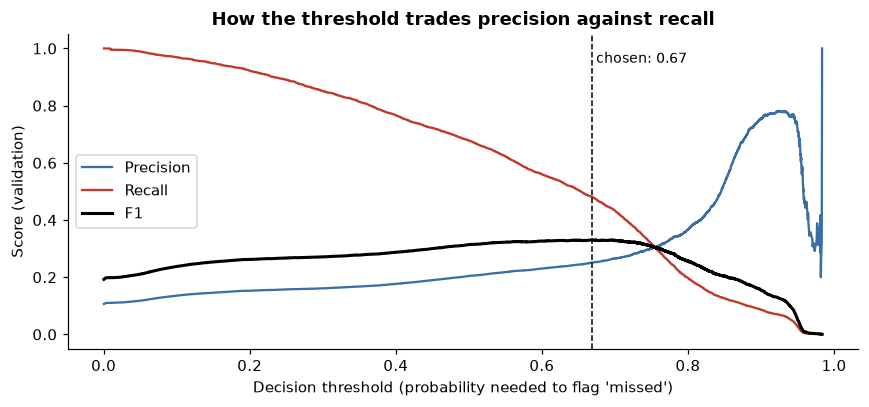

In [13]:
tuned_gb = clone(gb_pipe).set_params(**best_params)
tuned_gb.fit(train[gb_feats], y_train)
val_proba = tuned_gb.predict_proba(val[gb_feats])[:, 1]

prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1s = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
best_i = np.nanargmax(f1s[:-1])
THRESHOLD = float(thr[best_i])
print(f"Best threshold on validation: {THRESHOLD:.2f}  (F1 {f1s[best_i]:.3f} vs "
      f"{evaluate(y_val, val_proba)['F1']:.3f} at 0.5)")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(thr, prec[:-1], label="Precision", color=BLUE)
ax.plot(thr, rec[:-1], label="Recall", color=RED)
ax.plot(thr, f1s[:-1], label="F1", color="black", linewidth=2)
ax.axvline(THRESHOLD, color="black", linestyle="--", linewidth=1)
ax.text(THRESHOLD, 0.95, f" chosen: {THRESHOLD:.2f}", fontsize=9)
ax.set_xlabel("Decision threshold (probability needed to flag 'missed')")
ax.set_ylabel("Score (validation)")
ax.set_title("How the threshold trades precision against recall")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Final evaluation on the test set (Oct–Dec 2025)

Every model is now **retrained on Jan–Sep** (training + validation) and evaluated **once** on the untouched test set, using the same features and settings chosen above. This is the honest estimate of how each model would do on future requests.

In [14]:
final_models = dict(models)
final_models["Gradient boosting (tuned)"] = (clone(gb_pipe).set_params(**best_params), gb_feats)

test_rows = [{"Model": "Majority class (baseline floor)",
              **evaluate(y_test, np.zeros(len(y_test)))}]
baseline_pipe.fit(train_val[CAT_MIN], y_train_val)
test_rows.append({"Model": "Logistic regression, minimum features (baseline)",
                  **evaluate(y_test, baseline_pipe.predict_proba(test[CAT_MIN])[:, 1])})

test_proba = {}
for name, (pipe, feats) in final_models.items():
    pipe = clone(pipe)  # fresh, unfitted copy with the same settings
    pipe.fit(train_val[feats], y_train_val)
    test_proba[name] = pipe.predict_proba(test[feats])[:, 1]
    test_rows.append({"Model": name, **evaluate(y_test, test_proba[name])})
    if name == "Gradient boosting (tuned)":
        final_pipe = pipe
        test_rows.append({"Model": f"Gradient boosting (tuned) + threshold {THRESHOLD:.2f}  ← final",
                          **evaluate(y_test, test_proba[name], THRESHOLD)})

test_table = pd.DataFrame(test_rows).set_index("Model")
test_table.style.format("{:.3f}").highlight_max(axis=0, subset=["F1", "ROC-AUC", "PR-AUC"],
                                                props="font-weight: bold")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Majority class (baseline floor),0.895,0.000,0.000,0.000,0.500,0.105
"Logistic regression, minimum features (baseline)",0.893,0.350,0.023,0.043,0.781,0.320
Logistic regression,0.715,0.233,0.744,0.355,0.795,0.335
Decision tree,0.661,0.199,0.733,0.313,0.749,0.304
Random forest,0.816,0.310,0.609,0.410,0.790,0.351
Gradient boosting,0.725,0.239,0.740,0.361,0.797,0.336
Gradient boosting (tuned),0.717,0.234,0.747,0.357,0.795,0.331
Gradient boosting (tuned) + threshold 0.67 ← final,0.811,0.305,0.623,0.410,0.795,0.331


**What this means (test set, Oct–Dec):**
- **Final model vs. baseline:** F1 rose from **0.043 to 0.410**, and recall from **2% to 62%**. The baseline logistic regression ranks requests reasonably (ROC-AUC 0.78) but at the default cutoff almost never flags one, so it's useless in practice.
- **Most of the gain came from handling the imbalance (class weights) and choosing the cutoff (0.67)**, not from a fancier model. Tuned gradient boosting scores F1 0.357 at the 0.5 cutoff; moving the cutoff to 0.67 raises it to 0.410.
- **Tuning helped only slightly on validation (PR-AUC 0.297 → 0.300) and not on test (0.336 → 0.331).** Tuning doesn't guarantee improvement, and we report that honestly.
- **Random forest ties the final model on test F1 (0.410) and has a slightly higher PR-AUC (0.351 vs. 0.331).** We keep gradient boosting as the final model because it was chosen *before* seeing the test results; switching now would mean choosing by the test set. The honest conclusion is that gradient boosting and random forest perform about equally.
- The final model's accuracy (0.811) is lower than the majority class (0.895). That's expected: it gives up some accuracy in order to actually catch missed deadlines.

## 8. How the final model behaves on unseen data

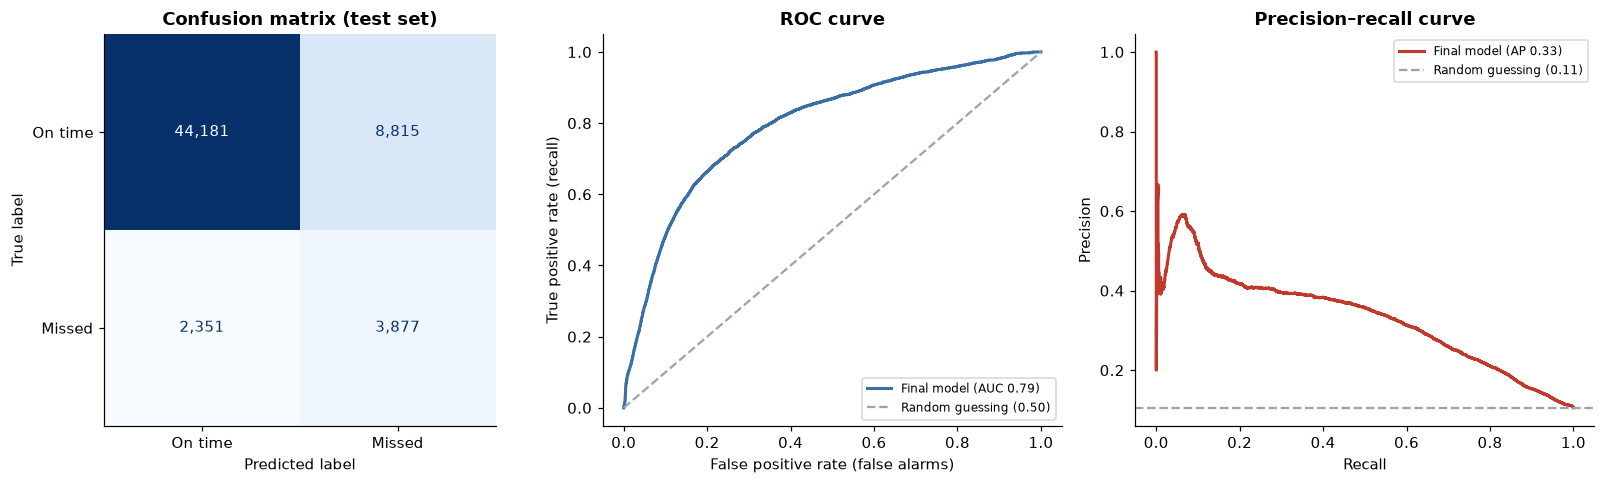

Caught 3,877 of 6,228 missed deadlines (recall 62%).
Of 12,692 requests flagged, 3,877 actually missed (precision 31%).
False alarms: 8,815  |  Missed deadlines not caught: 2,351


In [15]:
final_proba = test_proba["Gradient boosting (tuned)"]
final_pred = (final_proba >= THRESHOLD).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

cm = confusion_matrix(y_test, final_pred)
ConfusionMatrixDisplay(cm, display_labels=["On time", "Missed"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title("Confusion matrix (test set)")

fpr, tpr, _ = roc_curve(y_test, final_proba)
axes[1].plot(fpr, tpr, color=BLUE, linewidth=2,
             label=f"Final model (AUC {roc_auc_score(y_test, final_proba):.2f})")
axes[1].plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="Random guessing (0.50)")
axes[1].set_xlabel("False positive rate (false alarms)")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right", fontsize=8)

p, r, _ = precision_recall_curve(y_test, final_proba)
axes[2].plot(r, p, color=RED, linewidth=2,
             label=f"Final model (AP {average_precision_score(y_test, final_proba):.2f})")
axes[2].axhline(y_test.mean(), color=GRAY, linestyle="--",
                label=f"Random guessing ({y_test.mean():.2f})")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision–recall curve")
axes[2].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp:,} of {tp + fn:,} missed deadlines (recall {tp / (tp + fn):.0%}).")
print(f"Of {tp + fp:,} requests flagged, {tp:,} actually missed (precision {tp / (tp + fp):.0%}).")
print(f"False alarms: {fp:,}  |  Missed deadlines not caught: {fn:,}")

**What this means:**
- The model **catches 3,877 of 6,228 missed deadlines (62%)**. Of every 10 requests it flags, about **3 actually miss** (precision 31%).
- **8,815 false alarms vs. 2,351 uncaught misses.** For the city, a false alarm is cheap (a manager checks a request that would have been fine), while an uncaught miss means a resident waits past the promised date. Favoring recall is reasonable.
- The ROC curve sits well above random guessing (AUC 0.79), and PR-AUC is **3× random** (0.33 vs. 0.11): the model meaningfully ranks risky requests, though it's far from perfect.
- The cutoff is a policy choice: the city could lower it to catch more misses at the cost of more false alarms.

## 9. What the model learned

**Permutation importance:** shuffle one feature at a time on the test set and measure how much the model's PR-AUC drops. A big drop means the model relies heavily on that feature.

*Importance shows what the model uses, not what causes deadlines to be missed.*

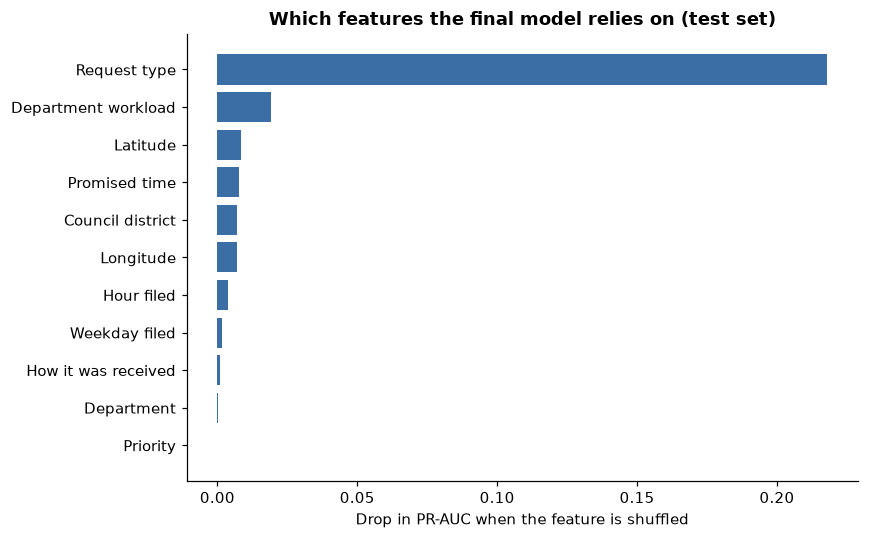

In [16]:
sample = test.sample(20000, random_state=SEED)
imp = permutation_importance(final_pipe, sample[gb_feats], sample["missed_deadline"],
                             scoring="average_precision", n_repeats=3,
                             random_state=SEED, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=gb_feats).sort_values()

nice = {"service_request_type": "Request type", "department": "Department", "priority": "Priority",
        "method_received_description": "How it was received", "city_council_district": "Council district",
        "promised_days": "Promised time", "dept_open_requests": "Department workload", "created_month": "Month filed", "created_weekday": "Weekday filed",
        "created_hour": "Hour filed", "latitude": "Latitude", "longitude": "Longitude"}

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([nice[c] for c in importance.index], importance.values, color=BLUE)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("Which features the final model relies on (test set)")
plt.tight_layout()
plt.show()

**What this means:**
- **Request type dominates.** Shuffling it drops PR-AUC by about 0.22, roughly 10× more than any other feature. *What* is requested matters far more than where or when.
- **Department workload, our engineered feature, is the 2nd most important.** It earned its place: tree models use it even though logistic regression couldn't (Section 4).
- Location (latitude, longitude, council district) and promised time add a little. Weekday, hour, intake method, department and priority add almost nothing once the request type is known (department and priority are mostly implied by the request type).
- This ordering is plausible: the EDA showed huge gaps between request types (Animal Nuisance misses 46% of the time, Dead Animal Pick Up 1%).

### Error analysis and fairness: does the model work equally well everywhere?

If the model catches missed deadlines well in some departments or districts but poorly in others, using it could make service *less* fair.

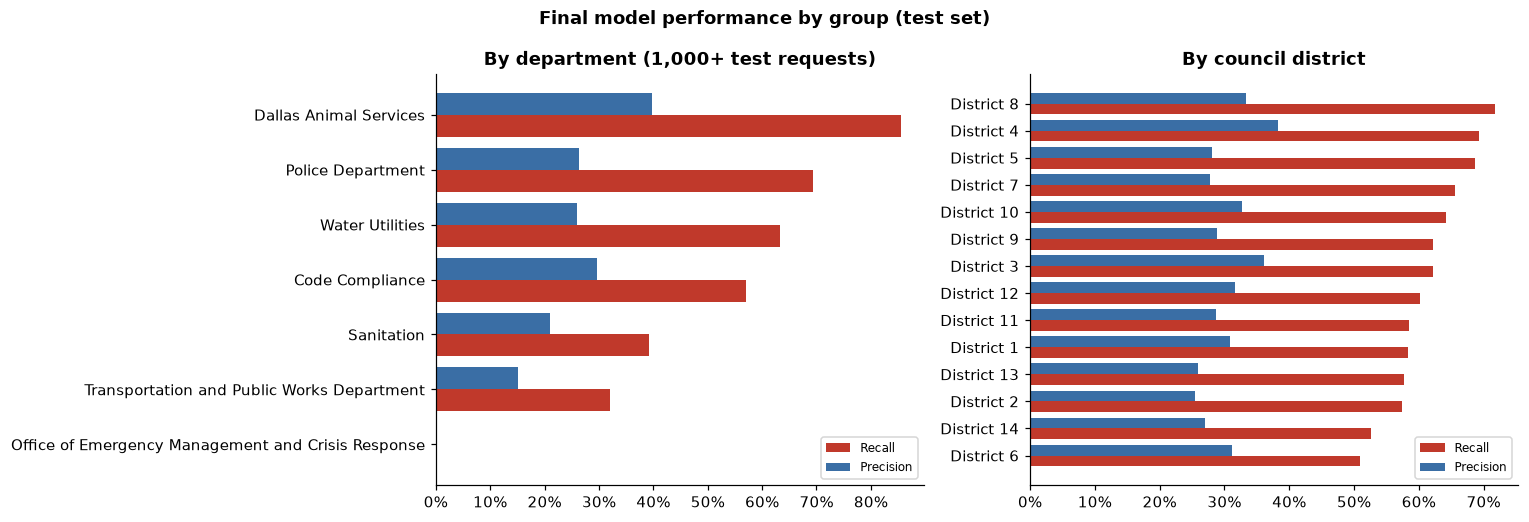

,requests,missed_rate,recall,precision
District 6,4808.0,0.104,0.510,0.311
District 14,5147.0,0.074,0.526,0.271
District 2,5403.0,0.089,0.574,0.255
District 13,3697.0,0.098,0.577,0.260
District 1,4592.0,0.094,0.584,0.309
District 11,2570.0,0.099,0.584,0.287
District 12,2094.0,0.106,0.602,0.316
District 3,3856.0,0.124,0.621,0.362
District 9,3647.0,0.094,0.622,0.289
District 10,2926.0,0.109,0.642,0.327


In [17]:
res = test.assign(pred=final_pred)

def group_scores(col, min_n=1000):
    out = res.groupby(col).apply(lambda g: pd.Series({
        "requests": len(g),
        "missed_rate": g["missed_deadline"].mean(),
        "recall": recall_score(g["missed_deadline"], g["pred"], zero_division=0),
        "precision": precision_score(g["missed_deadline"], g["pred"], zero_division=0),
    }))
    return out[out["requests"] >= min_n].sort_values("recall")

by_dept = group_scores("department")
by_dist = group_scores("city_council_district", min_n=500)
by_dist.index = [f"District {d}" for d in by_dist.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, tbl, title in [(ax1, by_dept, "By department (1,000+ test requests)"),
                       (ax2, by_dist, "By council district")]:
    y = np.arange(len(tbl))
    ax.barh(y - 0.2, tbl["recall"], height=0.4, color=RED, label="Recall")
    ax.barh(y + 0.2, tbl["precision"], height=0.4, color=BLUE, label="Precision")
    ax.set_yticks(y, tbl.index)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Final model performance by group (test set)", fontweight="bold")
plt.tight_layout()
plt.show()

by_dist.round(3)

**What this means:**
- **By department:** the model catches **about 86% of Animal Services misses** but only **about 32% of Transportation & Public Works misses** and 39% of Sanitation misses. It works best where misses are common and predictable from the request type. Street and pothole repairs likely depend on things the data doesn't capture, like crew availability and weather.
- **By council district:** recall ranges from **51% (District 6) to 72% (District 8)**; districts with higher missed rates tend to get higher recall. A city using this model would catch late requests more reliably in some districts than others, so any real use should monitor performance district by district.
- The EDA found that Districts 10–13 miss more often than their request mix predicts. The model doesn't treat them worse, but it also isn't designed to fix that gap.

## 10. Key findings: back to the four objectives

| Objective | Result |
| --- | --- |
| **1. Baseline** | Majority class: F1 0 (never catches a miss). Logistic regression on 5 features: test F1 0.043, ROC-AUC 0.78. |
| **2. Preprocessing & features** | Class weights tripled validation F1 (0.104 → 0.304). Rare-type grouping, promised time and timing features each added ≤ 0.004. Workload hurt logistic regression (−0.013) but became the 2nd most important feature for tree models. Removing "month filed" was essential, because it broke the tree models on unseen months. SMOTE didn't beat class weights. |
| **3. Model comparison** | Gradient boosting (chosen on validation PR-AUC) and random forest perform about equally on test. **Final model: tuned gradient boosting, cutoff 0.67: F1 0.410, recall 62%, precision 31%, ROC-AUC 0.80.** |
| **4. What drives missed deadlines** | Request type by far, then department workload. The model catches Animal Services misses well (86%) and Transportation & Public Works misses poorly (32%). Recall ranges from 51% to 72% across council districts. |

**Answer to the question:** *partly, yes.* At the moment a request is filed, the model can flag about 6 in 10 requests that will miss their deadline, mostly from the type of request and how busy the department is. It can't catch misses caused by things that aren't in the data.

## 11. Limitations
- **One year of data:** seasonality can't be learned, and the test months never appear in training.
- **Only closed requests:** requests still open when the data was downloaded are missing, so the longest-running cases may be underrepresented and the backlog is undercounted.
- **Missing drivers:** crew staffing, weather and budget likely matter a lot but aren't in the data.
- **Mixed clocks:** some deadlines count business days and others calendar days or hours, so "promised time" isn't measured on one consistent scale.
- **Association, not cause:** feature importance shows what the model uses, not what causes delays.
- **Modest precision (31%):** most flagged requests turn out to be false alarms.

## 12. Future work
- Add 2023–2024 data so the model can learn seasonal patterns.
- Add staffing and weather data.
- Choose the cutoff together with the city, based on the real cost of a missed deadline vs. a false alarm.
- If deployed, monitor performance by council district.